# Grammar scoring for spoken audio

In this challenge each recording is about a minute of someone speaking, and the goal is to predict a grammar score between 0 and 5. The score follows the rubric in the competition description, so it is about sentence structure and syntax, not about accent or how clear the voice is.

My plan is simple. Grammar shows up in the words a person says, so I first turn each recording into text with Whisper. Then I measure a few things about that text (how long and well formed the sentences are, how natural a language model finds it, and a sentence embedding), add a few basic audio measurements like how much of the clip is silence, and fit a small regularised model on top.

I went with this because there are only 769 labelled clips. Fine-tuning a large audio model on that little data would mostly memorise the training set. Using pretrained models only as feature extractors and keeping the final model small is a safer choice, and it is also easy to explain.

The leaderboard uses Pearson correlation and RMSE, so I report both. The task also asks for the RMSE on the training data, which I report as well, next to the cross-validated numbers that give a more honest picture.

## 1. Setup

In [1]:
import os, glob, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

# Find the competition files wherever Kaggle mounted them.
def find_first(pattern_list):
    for p in pattern_list:
        hits = glob.glob(p, recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(pattern_list)

TRAIN_CSV = find_first(["/kaggle/input/**/train.csv", "./train.csv"])
DATA_DIR  = os.path.dirname(TRAIN_CSV)
TEST_CSV  = os.path.join(DATA_DIR, "test.csv")
SAMPLE_SUB = glob.glob(os.path.join(DATA_DIR, "sample_submission.csv"))
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

train = pd.read_csv(TRAIN_CSV)
test  = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)

# IMPORTANT: train and test reuse the same file names (e.g. audio_8.wav exists in BOTH sets, and they are
# different recordings). So every clip gets a unique key = "<split>/<filename>", and the split is read
# from the folder the wav file sits in.
train["key"] = "train/" + train["filename"]
test["key"]  = "test/"  + test["filename"]

audio_paths = {}
for p in glob.glob(os.path.join(DATA_DIR, "**", "*.wav"), recursive=True):
    rel_dir = os.path.relpath(os.path.dirname(p), DATA_DIR).lower()
    split = "test" if "test" in rel_dir.split(os.sep) or "test" in rel_dir else "train"
    audio_paths[f"{split}/{os.path.basename(p)}"] = p
print("data dir:", DATA_DIR, "| wav files found:", len(audio_paths))

missing = [k for k in list(train["key"]) + list(test["key"]) if k not in audio_paths]
assert not missing, f"{len(missing)} audio files not found, e.g. {missing[:3]}. Check the folder layout (see the folder listing below)."
print("all", len(train), "train and", len(test), "test audio files located")

(769, 2) (216, 2)
data dir: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final | wav files found: 985
all 769 train and 216 test audio files located


## 2. A first look at the labels

Before building anything I want to see how the scores are spread. This also tells me what a model that learns nothing would score, so I know what I have to beat.

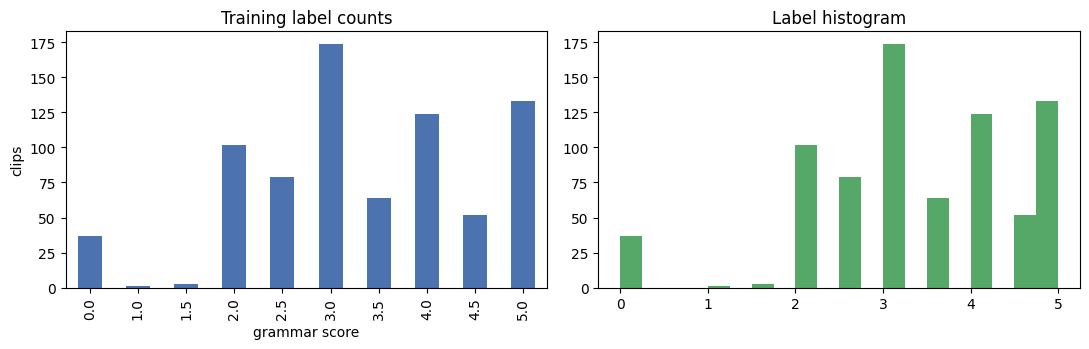

Predicting the mean for everyone gives RMSE = 1.238. Any useful model has to beat this.
Clips with score 0: 37 (0 is not in the rubric, so these are a special group - I look at what they are further down)


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
train["label"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Training label counts"); ax[0].set_xlabel("grammar score"); ax[0].set_ylabel("clips")
ax[1].hist(train["label"], bins=20, color="#55A868"); ax[1].set_title("Label histogram")
plt.tight_layout(); plt.show()

baseline_rmse = np.sqrt(np.mean((train["label"] - train["label"].mean()) ** 2))
print(f"Predicting the mean for everyone gives RMSE = {baseline_rmse:.3f}. Any useful model has to beat this.")
print("Clips with score 0:", int((train['label'] == 0).sum()),
      "(0 is not in the rubric, so these are a special group - I look at what they are further down)")

## 3. Audio features

These are plain signal measurements: the length of the clip, how much of it is actual speech, the number of pauses and how loud it is. Some training clips have a score of 0, which is not part of the rubric. I look at what those clips are in section 6.

In [3]:
import librosa

SR = 16000
def audio_feats(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    dur = len(y) / SR
    rms = librosa.feature.rms(y=y)[0]
    intervals = librosa.effects.split(y, top_db=30)
    speech_sec = sum(e - s for s, e in intervals) / SR
    return {"duration": dur,
            "speech_ratio": speech_sec / max(dur, 1e-6),
            "n_pauses": max(len(intervals) - 1, 0),
            "rms_mean": float(rms.mean()),
            "rms_std": float(rms.std())}

AF_PATH = os.path.join(WORK, "audio_feats.csv")
if os.path.exists(AF_PATH):
    af = pd.read_csv(AF_PATH)
else:
    names = list(train["key"]) + list(test["key"])
    af = pd.DataFrame([{"key": n, **audio_feats(audio_paths[n])} for n in names])
    af.to_csv(AF_PATH, index=False)
af.describe().T

,count,mean,std,min,25%,50%,75%,max
duration,985.0,54.240400,8.479730,6.480000,45.060000,60.074688,60.074688,61.040000
speech_ratio,985.0,0.732795,0.154124,0.038349,0.650018,0.729226,0.818892,1.000000
n_pauses,985.0,32.814213,16.017616,0.000000,26.000000,34.000000,43.000000,76.000000
rms_mean,985.0,0.042691,0.025191,0.001653,0.026493,0.041317,0.052508,0.167810
rms_std,985.0,0.037301,0.017593,0.001185,0.025314,0.039049,0.048890,0.119908


## 4. Speech to text with Whisper

Every clip is transcribed once and the transcripts are saved to a file, so I never have to repeat this slow step while experimenting. One thing to keep in mind is that Whisper often cleans up spoken grammar a little, so the transcript can look neater than what was really said. That is one reason I keep the audio features next to the text ones.

This step runs much faster on a GPU, and it needs Internet turned on in the notebook settings to download the model.

In [4]:
import torch
from transformers import pipeline

TR_PATH = os.path.join(WORK, "transcripts.csv")
if os.path.exists(TR_PATH):
    tr = pd.read_csv(TR_PATH).fillna("")
else:
    device = 0 if torch.cuda.is_available() else -1
    asr = pipeline("automatic-speech-recognition", model="openai/whisper-small",
                   device=device, chunk_length_s=30, torch_dtype=torch.float16 if device == 0 else torch.float32)
    names = list(train["key"]) + list(test["key"])
    texts = []
    for i in range(0, len(names), 16):
        batch = []
        for n in names[i:i + 16]:
            y, _ = librosa.load(audio_paths[n], sr=16000, mono=True)
            batch.append({"raw": y, "sampling_rate": 16000})
        out = asr(batch, batch_size=8, generate_kwargs={"language": "english", "task": "transcribe"})
        texts += [o["text"].strip() for o in out]
        print(f"{min(i + 16, len(names))}/{len(names)}", end="  ")
    tr = pd.DataFrame({"key": names, "text": texts})
    tr.to_csv(TR_PATH, index=False)
    del asr
tr["text"] = tr["text"].fillna("")
tr.sample(3, random_state=1)

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

...

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE 

16/985  32/985  48/985  64/985  80/985  96/985  112/985  128/985  144/985  160/985  

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


176/985  192/985  208/985  224/985  240/985  256/985  272/985  288/985  304/985  320/985  336/985  352/985  368/985  384/985  400/985  416/985  432/985  448/985  464/985  480/985  496/985  512/985  528/985  544/985  560/985  576/985  592/985  608/985  624/985  640/985  656/985  672/985  688/985  704/985  720/985  736/985  752/985  768/985  784/985  800/985  816/985  832/985  848/985  864/985  880/985  896/985  912/985  928/985  944/985  960/985  976/985  985/985  

,key,text
953,test/audio_212.wav,"Yeah, my TV show is one of the comedy show whi..."
236,train/audio_210.wav,My favorite hobby is beach going I enjoy the p...
484,train/audio_222.wav,"Okay, so one of my favorite places to visit is..."


## 5. Text features

I use three kinds of text features.

First, some simple counts that describe how fluent and structured the speech is: number of words, number of sentences, average sentence length, how varied the vocabulary is, filler words, immediately repeated words and the average word length.

Second, the average loss of GPT-2 on the transcript. Text with broken or unusual grammar is harder for a language model to predict, so the loss tends to be higher.

Third, a MiniLM sentence embedding, which is a short vector that summarises the transcript. It has many dimensions, so later I shrink it with PCA inside the model so that it does not drown out the smaller feature groups.

In [5]:
import zlib
FILLERS = {"um", "uh", "er", "erm", "hmm", "mm", "ah", "like"}

def text_feats(t):
    words = re.findall(r"[A-Za-z']+", t.lower())
    sents = [s for s in re.split(r"[.!?]+", t) if s.strip()]
    n = len(words)
    reps = sum(1 for a, b in zip(words, words[1:]) if a == b)
    trigrams = list(zip(words, words[1:], words[2:]))
    raw = t.encode("utf-8")
    return {"n_words": n,
            "n_sents": len(sents),
            "avg_sent_len": n / max(len(sents), 1),
            "ttr": len(set(words)) / max(n, 1),
            "filler_rate": sum(w in FILLERS for w in words) / max(n, 1),
            "repeat_rate": reps / max(n, 1),
            "avg_word_len": float(np.mean([len(w) for w in words])) if n else 0.0,
            # repetition measures: a transcript stuck in a loop compresses very well and has few distinct trigrams
            "compress_ratio": len(raw) / max(len(zlib.compress(raw)), 1),
            "distinct_3gram": len(set(trigrams)) / max(len(trigrams), 1)}

tf = pd.DataFrame([text_feats(t) for t in tr["text"]])
tf.insert(0, "key", tr["key"].values)
tf.head()

,key,n_words,n_sents,avg_sent_len,ttr,filler_rate,repeat_rate,avg_word_len,compress_ratio,distinct_3gram
0,train/audio_192.wav,89,5,17.800000,0.640449,0.044944,0.011236,3.966292,1.754864,0.977011
1,train/audio_436.wav,107,7,15.285714,0.476636,0.046729,0.000000,4.401869,1.973064,1.000000
2,train/audio_447.wav,146,12,12.166667,0.520548,0.006849,0.000000,3.979452,2.058333,0.930556
3,train/audio_126.wav,125,8,15.625000,0.360000,0.000000,0.032000,3.696000,2.433198,0.788618
4,train/audio_61.wav,78,5,15.600000,0.576923,0.000000,0.038462,3.807692,1.781395,0.973684


In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LM_PATH = os.path.join(WORK, "lm_loss.csv")
if os.path.exists(LM_PATH):
    lm = pd.read_csv(LM_PATH)
else:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained("gpt2")
    gpt = AutoModelForCausalLM.from_pretrained("gpt2").to(dev).eval()
    losses = []
    for t in tr["text"]:
        if len(t.split()) < 3:
            losses.append(np.nan); continue
        ids = tok(t, return_tensors="pt", truncation=True, max_length=512).input_ids.to(dev)
        with torch.no_grad():
            losses.append(gpt(ids, labels=ids).loss.item())
    lm = pd.DataFrame({"key": tr["key"], "lm_loss": losses})
    lm.to_csv(LM_PATH, index=False)
    del gpt
lm.describe().T

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


,count,mean,std,min,25%,50%,75%,max
lm_loss,985.0,3.575473,0.71352,0.172734,3.212565,3.58752,3.978086,6.16624


In [7]:
from sentence_transformers import SentenceTransformer

EMB_PATH = os.path.join(WORK, "embeddings.npy")
if os.path.exists(EMB_PATH):
    emb = np.load(EMB_PATH)
else:
    st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    emb = st.encode(list(tr["text"]), batch_size=64, show_progress_bar=False)
    np.save(EMB_PATH, emb)
print("embedding shape:", emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embedding shape: (985, 384)


## 5b. Audio embeddings from the Whisper encoder

So far the model only sees the words and a few crude audio numbers. The Whisper encoder has already learned to represent how speech sounds, including hesitations, restarts and unclear pronunciation, and none of that survives in the plain transcript. I run each clip through the encoder (in 30-second pieces, because that is the window Whisper works with), average its output over time, and keep two summaries: the last layer and a middle layer. Middle layers often keep more of the acoustic detail.

This is only a candidate. Later I check with cross-validation whether it really helps, and I keep it only if it does. If this step fails for any reason, the rest of the notebook still runs without it.

In [8]:
from transformers import WhisperFeatureExtractor, WhisperModel

WENC_PATH = os.path.join(WORK, "whisper_enc.npy")
if not os.path.exists(WENC_PATH):
    try:
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        fe  = WhisperFeatureExtractor.from_pretrained("openai/whisper-small")
        enc = WhisperModel.from_pretrained("openai/whisper-small").encoder.to(dev).eval()

        rows = []
        for n_done, key in enumerate(tr["key"], start=1):
            wav, _ = librosa.load(audio_paths[key], sr=SR, mono=True)
            # cut into pieces of at most 30 s and drop tails shorter than 1 s
            chunks = [wav[i:i + 30 * SR] for i in range(0, len(wav), 30 * SR)]
            chunks = [c for c in chunks if len(c) >= SR] or [np.zeros(SR, dtype=np.float32)]
            feats = fe(chunks, sampling_rate=SR, return_tensors="pt").input_features.to(dev)
            with torch.no_grad():
                out = enc(feats, output_hidden_states=True)
            last = out.last_hidden_state                          # (pieces, 1500, dim)
            mid = out.hidden_states[len(out.hidden_states) // 2]
            # the encoder gives 50 frames per second; only average over frames that hold real audio
            n_frames = [min(int(np.ceil(len(c) / SR * 50)), last.shape[1]) for c in chunks]
            wts = torch.tensor(n_frames, dtype=last.dtype, device=last.device)
            wts = (wts / wts.sum())[:, None]
            last_v = torch.stack([last[j, :n].mean(0) for j, n in enumerate(n_frames)])
            mid_v  = torch.stack([mid[j, :n].mean(0)  for j, n in enumerate(n_frames)])
            rows.append(np.stack([(last_v * wts).sum(0).float().cpu().numpy(),
                                  (mid_v * wts).sum(0).float().cpu().numpy()]))
            if n_done % 100 == 0:
                print(n_done, end="  ")
        np.save(WENC_PATH, np.stack(rows))                         # shape (clips, 2, dim)
        del enc
    except Exception as e:
        print("Whisper encoder embeddings could not be computed, continuing without them:", repr(e))
if os.path.exists(WENC_PATH):
    print("Whisper encoder embeddings:", np.load(WENC_PATH).shape)

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

100  200  300  400  500  600  700  800  900  Whisper encoder embeddings: (985, 2, 768)


## 5c. A larger Whisper encoder (medium)

Using more layers of the small encoder added almost nothing, so the next thing to try is a stronger encoder. Whisper-medium has about three times as many encoder layers and a wider representation, so it may capture more of how the speech sounds. It is computed in exactly the same way and saved separately, so the small-encoder features stay untouched. It is only a candidate, and the cross-validation check later decides whether it is kept. If this step fails, the rest of the notebook runs without it.

In [9]:
WENC_M_PATH = os.path.join(WORK, "whisper_enc_medium.npy")
if not os.path.exists(WENC_M_PATH):
    try:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        dtype = torch.float16 if dev == "cuda" else torch.float32     # half precision keeps the larger model fast on the GPU
        fe_m  = WhisperFeatureExtractor.from_pretrained("openai/whisper-medium")
        enc_m = WhisperModel.from_pretrained("openai/whisper-medium").encoder.to(dev).eval()
        if dev == "cuda":
            enc_m = enc_m.half()                                      # half precision keeps the larger model fast and small on the GPU

        rows = []
        for n_done, key in enumerate(tr["key"], start=1):
            wav, _ = librosa.load(audio_paths[key], sr=SR, mono=True)
            chunks = [wav[i:i + 30 * SR] for i in range(0, len(wav), 30 * SR)]
            chunks = [c for c in chunks if len(c) >= SR] or [np.zeros(SR, dtype=np.float32)]
            feats = fe_m(chunks, sampling_rate=SR, return_tensors="pt").input_features.to(dev, dtype)
            with torch.no_grad():
                out = enc_m(feats, output_hidden_states=True)
            last = out.last_hidden_state.float()
            mid = out.hidden_states[len(out.hidden_states) // 2].float()
            n_frames = [min(int(np.ceil(len(c) / SR * 50)), last.shape[1]) for c in chunks]
            wts = torch.tensor(n_frames, dtype=last.dtype, device=last.device)
            wts = (wts / wts.sum())[:, None]
            last_v = torch.stack([last[j, :n].mean(0) for j, n in enumerate(n_frames)])
            mid_v  = torch.stack([mid[j, :n].mean(0)  for j, n in enumerate(n_frames)])
            rows.append(np.stack([(last_v * wts).sum(0).cpu().numpy(), (mid_v * wts).sum(0).cpu().numpy()]))
            if n_done % 100 == 0:
                print(n_done, end="  ")
        np.save(WENC_M_PATH, np.stack(rows))                       # shape (clips, 2, dim)
        del enc_m
    except Exception as e:
        print("Whisper-medium embeddings could not be computed, continuing without them:", repr(e))
if os.path.exists(WENC_M_PATH):
    print("Whisper-medium embeddings:", np.load(WENC_M_PATH).shape)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.99k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

100  200  300  400  500  600  700  800  900  Whisper-medium embeddings: (985, 2, 1024)


## 5d. Several layers and a measure of spread from the medium encoder

So far I used only one summary of the medium encoder: the average of its last layer over the clip. Two things might add information. First, deeper and shallower layers capture different things, and the best layer for this task is not necessarily the last one. Second, an average hides how much the signal changes over time, and hesitations, restarts and uneven delivery are exactly that kind of change. So this step saves, for five layers, both the average and the standard deviation over time. As before, it is only a set of candidates: the cross-validation check decides whether any of them is kept, and if this step fails the notebook continues without it.

In [10]:
LAYERS = [8, 12, 16, 20, 24]           # medium has 24 layers; index 24 is the last one
WENC_ML_PATH = os.path.join(WORK, "whisper_enc_medium_layers.npy")
if not os.path.exists(WENC_ML_PATH):
    try:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        fe_m  = WhisperFeatureExtractor.from_pretrained("openai/whisper-medium")
        enc_m = WhisperModel.from_pretrained("openai/whisper-medium").encoder.to(dev).eval()
        dtype = torch.float32
        if dev == "cuda":
            enc_m = enc_m.half(); dtype = torch.float16

        rows = []
        for n_done, key in enumerate(tr["key"], start=1):
            wav, _ = librosa.load(audio_paths[key], sr=SR, mono=True)
            chunks = [wav[i:i + 30 * SR] for i in range(0, len(wav), 30 * SR)]
            chunks = [c for c in chunks if len(c) >= SR] or [np.zeros(SR, dtype=np.float32)]
            feats = fe_m(chunks, sampling_rate=SR, return_tensors="pt").input_features.to(dev, dtype)
            with torch.no_grad():
                out = enc_m(feats, output_hidden_states=True)
            n_frames = [min(int(np.ceil(len(c) / SR * 50)), out.hidden_states[0].shape[1]) for c in chunks]
            wts = torch.tensor(n_frames, dtype=torch.float32, device=dev)
            wts = (wts / wts.sum())[:, None]
            per_layer = []
            for L in LAYERS:
                h = out.hidden_states[L].float()
                m_j = torch.stack([h[j, :n].mean(0) for j, n in enumerate(n_frames)])              # mean per piece
                v_j = torch.stack([h[j, :n].var(0, unbiased=False) for j, n in enumerate(n_frames)])
                mean_all = (m_j * wts).sum(0)
                var_all = ((v_j + m_j ** 2) * wts).sum(0) - mean_all ** 2                           # variance over the whole clip
                per_layer.append(torch.stack([mean_all, var_all.clamp(min=0).sqrt()]))
            rows.append(torch.stack(per_layer).cpu().numpy())                                      # (layers, 2, dim)
            if n_done % 100 == 0:
                print(n_done, end="  ")
        np.save(WENC_ML_PATH, np.stack(rows))                                                      # (clips, layers, 2, dim)
        del enc_m
    except Exception as e:
        print("Multi-layer embeddings could not be computed, continuing without them:", repr(e))
if os.path.exists(WENC_ML_PATH):
    print("Multi-layer medium embeddings:", np.load(WENC_ML_PATH).shape)

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

100  200  300  400  500  600  700  800  900  Multi-layer medium embeddings: (985, 5, 2, 1024)


## 5e. More audio views: WavLM-large and Whisper large-v3-turbo

The biggest improvement so far came from letting the model hear the audio, and reading about speech assessment with frozen pretrained encoders points the same way: different encoders learn different things (WavLM and Whisper were trained very differently), the best layer depends on the task and is often not the last one, and a plain average over time can be complemented by the spread over time. So I add two more audio encoders, each saved at several layers with the mean and the standard deviation over time:

- **WavLM-large**, a self-supervised speech model that never sees transcripts, so it keeps pronunciation and rhythm.
- **Whisper large-v3-turbo**, the strongest Whisper encoder I can run comfortably on the GPU here.

They are candidates, not commitments. The cross-validation check decides which ones are kept, and a failure in either step just leaves it out.

In [11]:
import gc
from transformers import WhisperFeatureExtractor, WhisperModel

def check_and_save(rows, path):
    arr = np.stack(rows)
    if not np.isfinite(arr).all():
        raise ValueError("found non-finite values in the embeddings, not saving")
    np.save(path, arr)

# ---------- WavLM-large (full clip at once, full precision) ----------
from transformers import AutoFeatureExtractor, AutoModel

WAVLM_LAYERS = [8, 12, 16, 20, 24]
WAVLM_PATH = os.path.join(WORK, "wavlm_large_layers.npy")
if not os.path.exists(WAVLM_PATH):
    try:
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        fe_w = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-large")
        wavlm = AutoModel.from_pretrained("microsoft/wavlm-large").to(dev).eval()
        rows = []
        for n_done, key in enumerate(tr["key"], start=1):
            wav, _ = librosa.load(audio_paths[key], sr=SR, mono=True)
            wav = wav[: 62 * SR]
            inp = fe_w(wav, sampling_rate=SR, return_tensors="pt").input_values.to(dev)
            with torch.no_grad():
                out = wavlm(inp, output_hidden_states=True)
            per_layer = []
            for L in WAVLM_LAYERS:
                h = out.hidden_states[L][0].float()                       # (frames, dim)
                per_layer.append(torch.stack([h.mean(0), h.std(0)]))
            rows.append(torch.stack(per_layer).cpu().numpy())           # (layers, 2, dim)
            if n_done % 100 == 0:
                print(n_done, end="  ")
        check_and_save(rows, WAVLM_PATH)
        del wavlm
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception as e:
        print("WavLM embeddings could not be computed, continuing without them:", repr(e))
if os.path.exists(WAVLM_PATH):
    print("WavLM-large embeddings:", np.load(WAVLM_PATH).shape)

# ---------- Whisper large-v3-turbo encoder (30 s pieces, half precision) ----------
TURBO_LAYERS = [8, 16, 24, 32]
TURBO_PATH = os.path.join(WORK, "whisper_turbo_layers.npy")
if not os.path.exists(TURBO_PATH):
    try:
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        fe_t  = WhisperFeatureExtractor.from_pretrained("openai/whisper-large-v3-turbo")
        enc_t = WhisperModel.from_pretrained("openai/whisper-large-v3-turbo").encoder.to(dev).eval()
        dtype = torch.float32
        if dev == "cuda":
            enc_t = enc_t.half(); dtype = torch.float16
        rows = []
        for n_done, key in enumerate(tr["key"], start=1):
            wav, _ = librosa.load(audio_paths[key], sr=SR, mono=True)
            chunks = [wav[i:i + 30 * SR] for i in range(0, len(wav), 30 * SR)]
            chunks = [c for c in chunks if len(c) >= SR] or [np.zeros(SR, dtype=np.float32)]
            feats = fe_t(chunks, sampling_rate=SR, return_tensors="pt").input_features.to(dev, dtype)
            with torch.no_grad():
                out = enc_t(feats, output_hidden_states=True)
            n_frames = [min(int(np.ceil(len(c) / SR * 50)), out.hidden_states[0].shape[1]) for c in chunks]
            wts = torch.tensor(n_frames, dtype=torch.float32, device=dev)
            wts = (wts / wts.sum())[:, None]
            per_layer = []
            for L in TURBO_LAYERS:
                h = out.hidden_states[L].float()
                m_j = torch.stack([h[j, :n].mean(0) for j, n in enumerate(n_frames)])
                v_j = torch.stack([h[j, :n].var(0, unbiased=False) for j, n in enumerate(n_frames)])
                mean_all = (m_j * wts).sum(0)
                var_all = ((v_j + m_j ** 2) * wts).sum(0) - mean_all ** 2
                per_layer.append(torch.stack([mean_all, var_all.clamp(min=0).sqrt()]))
            rows.append(torch.stack(per_layer).cpu().numpy())
            if n_done % 100 == 0:
                print(n_done, end="  ")
        check_and_save(rows, TURBO_PATH)
        del enc_t
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception as e:
        print("Whisper-turbo embeddings could not be computed, continuing without them:", repr(e))
if os.path.exists(TURBO_PATH):
    print("Whisper-turbo embeddings:", np.load(TURBO_PATH).shape)

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

...

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.62GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

100  200  300  400  500  600  700  800  900  Whisper-turbo embeddings: (985, 4, 2, 1280)


## 5f. A language model reads the transcript against the rubric

The transcript features so far (counts, GPT-2 loss, a small sentence embedding) are weak: the text-only model was far behind the audio one. A better text signal is to let an instruction-tuned language model read the transcript and the rubric, and give a grade. I use Qwen2.5-3B-Instruct, a small open model that fits on the GPU. Instead of letting it write text, I look at how much probability it puts on each digit from 1 to 5 as the next token, and keep the expected grade and the five probabilities as six numeric features.

This is a rough judge, and its output is just six more columns for the regression, which can ignore them if they do not help. The ablation table later shows whether they did.

In [12]:
import gc
LLM_PATH = os.path.join(WORK, "llm_judge.csv")
NL = chr(10)
RUBRIC = NL.join([
    "1: struggles with proper sentence structure and syntax; limited control over simple structures and memorised patterns.",
    "2: limited understanding of sentence structure; simple structures with consistent basic mistakes; sentences may be left incomplete.",
    "3: decent grasp of sentence structure but errors in grammar, or decent grammar but errors in sentence syntax and structure.",
    "4: strong understanding of structure and syntax; good control of grammar; occasional minor errors that do not cause misunderstanding.",
    "5: high grammatical accuracy and control of complex grammar; seldom makes noticeable mistakes; corrects itself when necessary."])

if not os.path.exists(LLM_PATH):
    try:
        from transformers import AutoTokenizer, AutoModelForCausalLM
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        qname = "Qwen/Qwen2.5-3B-Instruct"
        tok_q = AutoTokenizer.from_pretrained(qname)
        llm = AutoModelForCausalLM.from_pretrained(qname).to(dev).eval()
        if dev == "cuda":
            llm = llm.half()
        digit_ids = [tok_q.encode(str(d), add_special_tokens=False)[0] for d in range(1, 6)]

        out_rows = []
        for n_done, (key, text) in enumerate(zip(tr["key"], tr["text"]), start=1):
            text = " ".join(str(text).split()[:700]) or "(no speech)"
            msgs = [
                {"role": "system", "content": "You are an experienced examiner of spoken English."},
                {"role": "user", "content": "Below is an automatic transcript of a candidate speaking English for about one minute. "
                    "Judge the candidate's GRAMMAR (sentence structure and syntax), using this rubric:" + NL + RUBRIC + NL + NL +
                    "Transcript:" + NL + text + NL + NL + "Answer with a single digit from 1 to 5."}]
            prompt = tok_q.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
            ids = tok_q(prompt, return_tensors="pt").input_ids.to(dev)
            with torch.no_grad():
                logits = llm(ids).logits[0, -1].float()
            p = torch.softmax(logits[digit_ids], dim=0).cpu().numpy()
            out_rows.append({"key": key, "llm_exp": float((p * np.arange(1, 6)).sum()),
                             **{f"llm_p{d}": float(p[d - 1]) for d in range(1, 6)}})
            if n_done % 100 == 0:
                print(n_done, end="  ")
        pd.DataFrame(out_rows).to_csv(LLM_PATH, index=False)
        del llm
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception as e:
        print("LLM judge features could not be computed, continuing without them:", repr(e))
if os.path.exists(LLM_PATH):
    display(pd.read_csv(LLM_PATH).describe().T.round(3))

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

100  200  300  400  500  600  700  800  900  

,count,mean,std,min,25%,50%,75%,max
llm_exp,985.0,2.574,0.694,1.0,2.188,2.635,2.991,4.894
llm_p1,985.0,0.136,0.258,0.0,0.002,0.016,0.116,1.000
llm_p2,985.0,0.297,0.219,0.0,0.101,0.269,0.473,0.960
llm_p3,985.0,0.440,0.249,0.0,0.235,0.466,0.641,0.939
llm_p4,985.0,0.111,0.164,0.0,0.009,0.035,0.141,0.880
llm_p5,985.0,0.016,0.076,0.0,0.000,0.000,0.002,0.906


## 6. Putting the features together

A few clips have almost no words, so the language model loss is missing for them. I fill those with the training median and add a flag column, so the model can still tell that the value was missing.

In [13]:
feat = af.merge(tf, on="key").merge(lm, on="key")
if os.path.exists(LLM_PATH):                       # six numeric features from the language-model judge
    feat = feat.merge(pd.read_csv(LLM_PATH), on="key")
feat["lm_missing"] = feat["lm_loss"].isna().astype(int)
feat["lm_loss"] = feat["lm_loss"].fillna(feat.loc[feat.key.str.startswith("train/"), "lm_loss"].median())
feat["words_per_sec"] = feat["n_words"] / feat["duration"].clip(lower=1)
feat["words_per_speech_sec"] = feat["n_words"] / (feat["duration"] * feat["speech_ratio"]).clip(lower=1)

HAND = [c for c in feat.columns if c != "key"]
emb_df = pd.DataFrame(emb, columns=[f"emb_{i}" for i in range(emb.shape[1])])
emb_df.insert(0, "key", tr["key"].values)
full = feat.merge(emb_df, on="key")

# Whisper encoder embeddings (two summaries per clip: last layer and a middle layer)
WENC_LAST, WENC_MID = [], []
if os.path.exists(WENC_PATH):
    wenc = np.load(WENC_PATH)                                   # (clips, 2, dim), same clip order as the transcripts
    WENC_LAST = [f"wl_{i}" for i in range(wenc.shape[2])]
    WENC_MID  = [f"wm_{i}" for i in range(wenc.shape[2])]
    wdf = pd.DataFrame(np.hstack([wenc[:, 0, :], wenc[:, 1, :]]), columns=WENC_LAST + WENC_MID)
    wdf.insert(0, "key", tr["key"].values)
    full = full.merge(wdf, on="key")

# Whisper-medium encoder embeddings (optional, same layout as above)
WENC_M_LAST, WENC_M_MID = [], []
if os.path.exists(WENC_M_PATH):
    wenc_m = np.load(WENC_M_PATH)
    WENC_M_LAST = [f"ml_{i}" for i in range(wenc_m.shape[2])]
    WENC_M_MID  = [f"mm_{i}" for i in range(wenc_m.shape[2])]
    wdf_m = pd.DataFrame(np.hstack([wenc_m[:, 0, :], wenc_m[:, 1, :]]), columns=WENC_M_LAST + WENC_M_MID)
    wdf_m.insert(0, "key", tr["key"].values)
    full = full.merge(wdf_m, on="key")

# Multi-layer medium embeddings: mean and spread for each saved layer
WLAYER = {}
if os.path.exists(WENC_ML_PATH):
    wl = np.load(WENC_ML_PATH)                                  # (clips, layers, 2, dim)
    n_c, n_l, _, d_l = wl.shape
    names_l = []
    for L in LAYERS:
        for stat in ["mean", "std"]:
            WLAYER[(L, stat)] = [f"ml{L}_{stat}_{i}" for i in range(d_l)]
            names_l += WLAYER[(L, stat)]
    wdf_l = pd.DataFrame(wl.reshape(n_c, -1), columns=names_l)  # order: layer, statistic, dimension
    wdf_l.insert(0, "key", tr["key"].values)
    full = full.merge(wdf_l, on="key")

# More audio views, each stored as {(layer, statistic): [column names]}
def load_layer_family(path, layers, prefix):
    fam = {}
    if not os.path.exists(path):
        return fam, None
    arr = np.load(path)                                          # (clips, layers, 2, dim)
    n_c, _, _, d = arr.shape
    names = []
    for L in layers:
        for stat in ["mean", "std"]:
            fam[(L, stat)] = [f"{prefix}{L}_{stat}_{i}" for i in range(d)]
            names += fam[(L, stat)]
    df = pd.DataFrame(arr.reshape(n_c, -1), columns=names)      # order: layer, statistic, dimension
    df.insert(0, "key", tr["key"].values)
    return fam, df

WAVLM, df_wv = load_layer_family(WAVLM_PATH, WAVLM_LAYERS, "wv")
TURBO, df_tb = load_layer_family(TURBO_PATH, TURBO_LAYERS, "tb")
for df_extra in (df_wv, df_tb):
    if df_extra is not None:
        full = full.merge(df_extra, on="key")
EMB = [c for c in full.columns if c.startswith("emb_")]

tr_df = train.merge(full, on="key", how="left")
te_df = test[["filename", "key"]].merge(full, on="key", how="left")
ALL_NEW = HAND + EMB + WENC_LAST + WENC_MID + WENC_M_LAST + WENC_M_MID + [c for cols in WLAYER.values() for c in cols] + [c for cols in WAVLM.values() for c in cols] + [c for cols in TURBO.values() for c in cols]
assert tr_df[ALL_NEW].notna().all().all() and te_df[ALL_NEW].notna().all().all()
y = tr_df["label"].values
print("hand-made features:", len(HAND), "| embedding dims:", len(EMB))

# Do the zero-score clips really look different?
print(tr_df.assign(is_zero=(tr_df.label == 0)).groupby("is_zero")[["n_words", "speech_ratio", "rms_mean", "duration", "lm_loss", "compress_ratio", "distinct_3gram"]].mean().round(3))

hand-made features: 24 | embedding dims: 384
         n_words  speech_ratio  rms_mean  duration  lm_loss  compress_ratio  \
is_zero                                                                       
False    100.997         0.704     0.041    55.676    3.595           1.938   
True     233.243         1.000     0.120    57.864    2.728           5.795   

         distinct_3gram  
is_zero                  
False             0.962  
True              0.700  


## 7. Model and validation

The hand-made features are standardised. The embedding is standardised and then reduced with PCA. On top of that I fit two simple regressors, Ridge and an SVR, and average their predictions. Both are fairly strongly regularised, which is my main protection against overfitting on such a small dataset.

For validation I use 5-fold cross-validation repeated three times, with the folds balanced by score. The scaling and PCA sit inside the sklearn pipeline, so each fold learns them only from its own training part and nothing leaks in from the clips being scored.

How I read the numbers: if the training RMSE is much lower than the cross-validated RMSE, the model is overfitting. If both are bad, it is underfitting and what is missing is better features, not a bigger model.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.model_selection import StratifiedKFold

# Whisper-encoder columns that are switched on (decided by cross-validation below).
# The "not in globals()" guard means that re-running this cell later does NOT switch them off again.
if "WENC" not in globals():
    WENC = []

# Model settings. These start at the values I used first and may be adjusted by the tuning step below.
P = {"n_pca_emb": 24, "n_pca_wenc": 24, "alpha": 30.0, "C": 1.0}

def make_model(kind):
    blocks = [
        ("hand", StandardScaler(), HAND),
        ("emb", Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=int(P["n_pca_emb"]), random_state=SEED))]), EMB),
    ]
    if len(WENC) > 0:
        blocks.append(("wenc", Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=int(P["n_pca_wenc"]), random_state=SEED))]), WENC))
    reg = Ridge(alpha=P["alpha"]) if kind == "ridge" else SVR(C=P["C"], epsilon=0.3, gamma="scale")
    return Pipeline([("pre", ColumnTransformer(blocks)), ("reg", reg)])

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

# Balance the folds: the score-0 clips get their own group, and the rare 1.0/1.5 scores join the 2.0 group.
strata = np.where(y == 0, 0, np.clip(np.round(y * 2) / 2, 2.0, 5.0) * 2).astype(int)   # integer class ids
nz = y > 0                                   # mask for the "normal" clips (score 1 to 5)
X = tr_df[HAND + EMB + WENC]

def repeated_cv(kinds, n_repeats=3, drop_zero_train=False):
    oof = {k: np.zeros((n_repeats, len(y))) for k in kinds}
    for r in range(n_repeats):
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED + r)
        for tri, vai in skf.split(X, strata):
            for k in kinds:
                fit_idx = tri[y[tri] > 0] if drop_zero_train else tri
                m = make_model(k).fit(X.iloc[fit_idx], y[fit_idx])
                oof[k][r, vai] = m.predict(X.iloc[vai])
    return oof

def summarize(o, mask):
    p = np.clip(o, 0, 5)
    rm = [rmse(y[mask], p[r][mask]) for r in range(len(p))]
    pe = [pearsonr(y[mask], p[r][mask])[0] for r in range(len(p))]
    return np.mean(rm), np.std(rm), np.mean(pe)

allm = np.ones(len(y), bool)
base_nz = float(np.std(y[nz]))

### Do the Whisper-encoder audio embeddings help?

I use the same cross-validation as everywhere else: Ridge, zero clips left out of training, scored on the normal clips only. I keep an option only if it lowers the RMSE by at least 0.005 compared with the current features, because a smaller difference is within the noise of this validation. The same rule decides whether a larger or different encoder (medium, WavLM-large, Whisper-turbo, or one of their layers) replaces the small one. If a set of embeddings was not computed, it is simply left out of the comparison.

In [15]:
def cv_with(wenc_cols, n_repeats=2):
    global WENC, X
    saved = (WENC, X)
    WENC = wenc_cols
    X = tr_df[HAND + EMB + WENC]
    try:
        o = repeated_cv(["ridge"], n_repeats, drop_zero_train=True)["ridge"]
    finally:
        WENC, X = saved
    return summarize(o, nz)

base_name = "current features (no encoder embeddings)"
small_cands = {base_name: []}
if WENC_LAST:
    small_cands["+ small encoder, last layer"]   = WENC_LAST
    small_cands["+ small encoder, middle layer"] = WENC_MID
    small_cands["+ small encoder, both layers"]  = WENC_LAST + WENC_MID
medium_cands = {}
if WENC_M_LAST:
    medium_cands["+ medium encoder, last layer"]  = WENC_M_LAST
    medium_cands["+ medium encoder, both layers"] = WENC_M_LAST + WENC_M_MID
    if WENC_LAST:
        medium_cands["+ small and medium, both layers"] = WENC_LAST + WENC_MID + WENC_M_LAST + WENC_M_MID
if WLAYER:
    layers_here = sorted({k[0] for k in WLAYER})
    for L in layers_here:
        medium_cands[f"+ medium layer {L}, mean"] = WLAYER[(L, "mean")]
    for L in layers_here:
        medium_cands[f"+ medium layer {L}, mean + spread"] = WLAYER[(L, "mean")] + WLAYER[(L, "std")]
    deep = [L for L in layers_here if L >= 16]
    if len(deep) >= 2:
        medium_cands["+ medium layers " + ", ".join(map(str, deep)) + ", mean"] = sum((WLAYER[(L, "mean")] for L in deep), [])
for fam_name, fam in [("WavLM-large", WAVLM), ("Whisper-turbo", TURBO)]:
    for L in sorted({k[0] for k in fam}):
        medium_cands[f"+ {fam_name} layer {L}, mean + spread"] = fam[(L, "mean")] + fam[(L, "std")]
cands = {**small_cands, **medium_cands}

res_w = {name: cv_with(cols) for name, cols in cands.items()}
tab_w = pd.DataFrame(res_w, index=["RMSE (score>0)", "RMSE std", "Pearson (score>0)"]).T.round(3)

# Step 1: best small-encoder option, kept only if it beats the current features by at least 0.005.
best_small = min(small_cands, key=lambda k: res_w[k][0])
chosen = best_small if res_w[base_name][0] - res_w[best_small][0] >= 0.005 else base_name
# Step 2: a medium-encoder option replaces that choice only if it beats it by at least 0.005 as well.
if medium_cands:
    best_med = min(medium_cands, key=lambda k: res_w[k][0])
    if res_w[chosen][0] - res_w[best_med][0] >= 0.005:
        chosen = best_med
WENC = cands[chosen]
X = tr_df[HAND + EMB + WENC]
print("Chosen feature set:", chosen)
print(f"Mean-predictor reference on the score>0 clips: RMSE {base_nz:.3f}")
tab_w

Chosen feature set: + medium layer 20, mean + spread
Mean-predictor reference on the score>0 clips: RMSE 1.014


,RMSE (score>0),RMSE std,Pearson (score>0)
current features (no encoder embeddings),0.706,0.006,0.718
"+ small encoder, last layer",0.575,0.009,0.824
"+ small encoder, middle layer",0.591,0.009,0.813
"+ small encoder, both layers",0.571,0.007,0.826
"+ medium encoder, last layer",0.562,0.009,0.832
"+ medium encoder, both layers",0.564,0.008,0.831
"+ small and medium, both layers",0.572,0.006,0.826
"+ medium layer 8, mean",0.627,0.008,0.785
"+ medium layer 12, mean",0.567,0.010,0.829
"+ medium layer 16, mean",0.572,0.007,0.825


### Tuning the model settings

The encoder embeddings turned out to matter a lot, but the model settings were picked before they existed: the audio block is squeezed into 24 PCA components, and the Ridge strength and SVR setting were fixed by hand. So I try a few values for each, one setting at a time, always keeping the best value found so far. Each setting is scored by the cross-validated RMSE of the final model (Ridge and SVR averaged, zero clips included), and I change a setting only if it lowers the RMSE by at least 0.005. The grid is small on purpose. The more values I try, the more likely it is that one wins by luck, and that would make the cross-validation number look better than the model really is.

In [16]:
print("Features in use -> hand-made:", len(HAND), "| text embedding:", len(EMB), "| audio-encoder columns:", len(WENC))
assert not (WENC_LAST and not WENC), "Encoder features are switched off. Run the encoder comparison cell above first, then this one."

def tune_stage(name, values, n_repeats=2):
    # try each value of one setting, keep the others as they are
    out = []
    for v in values:
        old = P[name]; P[name] = v
        try:
            o = repeated_cv(["ridge", "svr"], n_repeats)
            blend = (o["ridge"] + o["svr"]) / 2
            out.append({"setting": name, "value": v,
                        "RMSE all": summarize(blend, allm)[0],
                        "RMSE score>0": summarize(blend, nz)[0],
                        "Pearson score>0": summarize(blend, nz)[2]})
        finally:
            P[name] = old
    return pd.DataFrame(out)

grids = {"n_pca_wenc": [12, 24, 48, 96] if WENC else [P["n_pca_wenc"]],
         "n_pca_emb":  [8, 24, 48],
         "alpha":      [10.0, 30.0, 100.0, 300.0],
         "C":          [0.5, 1.0, 3.0]}

tried = []
for name, values in grids.items():
    t = tune_stage(name, values)
    cur = t[t["value"] == P[name]]["RMSE all"].iloc[0]          # score of the current setting
    best_row = t.loc[t["RMSE all"].idxmin()]
    if cur - best_row["RMSE all"] >= 0.005:
        P[name] = type(P[name])(best_row["value"])        # keep ints as ints and floats as floats
    tried.append(t)

tune_table = pd.concat(tried, ignore_index=True)
tune_table["value"] = tune_table["value"].map(lambda v: f"{v:g}")
tune_table = tune_table.round(3)
print("Settings used from here on:", P)
tune_table

Features in use -> hand-made: 24 | text embedding: 384 | audio-encoder columns: 2048
Settings used from here on: {'n_pca_emb': 24, 'n_pca_wenc': 96, 'alpha': 30.0, 'C': 3.0}


,setting,value,RMSE all,RMSE score>0,Pearson score>0
0,n_pca_wenc,12,0.570,0.562,0.833
1,n_pca_wenc,24,0.559,0.550,0.841
2,n_pca_wenc,48,0.549,0.543,0.846
3,n_pca_wenc,96,0.544,0.537,0.849
4,n_pca_emb,8,0.550,0.543,0.845
5,n_pca_emb,24,0.544,0.537,0.849
6,n_pca_emb,48,0.544,0.537,0.849
7,alpha,10,0.544,0.537,0.849
8,alpha,30,0.544,0.537,0.849
9,alpha,100,0.544,0.537,0.849


### Baseline results with the chosen features

In [17]:
oof = repeated_cv(["ridge", "svr"])
oof["blend"] = (oof["ridge"] + oof["svr"]) / 2

rows = []
for k, p in oof.items():
    a = summarize(p, allm); b = summarize(p, nz)
    rows.append({"model": k, "CV RMSE": a[0], "CV RMSE std": a[1], "CV Pearson": a[2],
                 "RMSE (score>0 only)": b[0], "Pearson (score>0 only)": b[2]})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
print(f"Mean-predictor RMSE for reference: {baseline_rmse:.3f} on all clips, {base_nz:.3f} on the score>0 clips")
cv_table

Mean-predictor RMSE for reference: 1.238 on all clips, 1.014 on the score>0 clips


,CV RMSE,CV RMSE std,CV Pearson,RMSE (score>0 only),Pearson (score>0 only)
model,,,,,
ridge,0.563,0.011,0.891,0.562,0.832
svr,0.561,0.002,0.893,0.541,0.846
blend,0.537,0.006,0.902,0.532,0.852


### Should the score-0 clips be used for training?

All 37 clips with a score of 0 come from a separate block of file numbers (5037 to 5073), and every other training clip is numbered below 800 and scored 1 to 5. So they look like a different kind of recording, and I am not sure the test set contains any. Since the test set is the thing that matters, I compare two options using only the normal clips (score above 0) for scoring: train with the zero clips included, or leave them out of training. The numbers decide which one I use.

In [18]:
oof_nz = repeated_cv(["ridge", "svr"], drop_zero_train=True)
oof_nz["blend"] = (oof_nz["ridge"] + oof_nz["svr"]) / 2

cmp = pd.DataFrame({
    "trained WITH zero clips":    summarize(oof["blend"], nz),
    "trained WITHOUT zero clips": summarize(oof_nz["blend"], nz),
}, index=["RMSE (score>0 clips)", "RMSE std", "Pearson (score>0 clips)"]).T.round(3)
print(f"For reference, predicting the mean on the score>0 clips gives RMSE {base_nz:.3f}")
cmp

For reference, predicting the mean on the score>0 clips gives RMSE 1.014


,RMSE (score>0 clips),RMSE std,Pearson (score>0 clips)
trained WITH zero clips,0.532,0.005,0.852
trained WITHOUT zero clips,0.528,0.004,0.854


### A two-step version that handles the zero clips explicitly

A single Ridge or SVR cannot easily jump from a score near 3 down to 0, so the zero clips pull the whole model around. In the test set a few clips look like the zero group (a quick check with a classifier flagged about 4 percent of them), and each one that gets predicted around 3 instead of 0 costs a lot of RMSE.

So I split the job in two. A logistic regression looks at a few simple signals (speech ratio, loudness, word count, repetition, language model loss) and estimates the probability that a clip belongs to the zero group. The regressors from before are trained only on the normal clips. The final prediction is (1 - probability of zero) times the regressor score. That is the expected score, which is what RMSE rewards.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

ZCOLS = ["speech_ratio", "rms_mean", "n_words", "compress_ratio", "distinct_3gram", "lm_loss"]
def make_zero_clf():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def two_stage_cv(n_repeats=3):
    out = np.zeros((n_repeats, len(y)))
    is_zero = (y == 0).astype(int)
    for r in range(n_repeats):
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED + r)
        for tri, vai in skf.split(X, strata):
            pz = make_zero_clf().fit(tr_df[ZCOLS].iloc[tri], is_zero[tri]).predict_proba(tr_df[ZCOLS].iloc[vai])[:, 1]
            keep = tri[y[tri] > 0]
            reg = np.mean([make_model(k).fit(X.iloc[keep], y[keep]).predict(X.iloc[vai]) for k in ["ridge", "svr"]], axis=0)
            out[r, vai] = (1 - pz) * np.clip(reg, 0, 5)
    return out

oof_ts = two_stage_cv()
res = pd.DataFrame({
    "one model, zero clips included": [*summarize(oof["blend"], allm), *summarize(oof["blend"], nz)],
    "two-step version":               [*summarize(oof_ts, allm),      *summarize(oof_ts, nz)],
}, index=["RMSE all", "RMSE std all", "Pearson all", "RMSE score>0", "RMSE std score>0", "Pearson score>0"]).T.round(3)
print(f"Mean-predictor reference: {baseline_rmse:.3f} on all clips, {base_nz:.3f} on score>0 clips")
res

Mean-predictor reference: 1.238 on all clips, 1.014 on score>0 clips


,RMSE all,RMSE std all,Pearson all,RMSE score>0,RMSE std score>0,Pearson score>0
"one model, zero clips included",0.537,0.006,0.902,0.532,0.005,0.852
two-step version,0.555,0.004,0.894,0.541,0.005,0.846


In [20]:
# Use the two-step version only if it is better on all clips (lower RMSE). You can overwrite these by hand.
USE_TWO_STAGE = bool(summarize(oof_ts, allm)[0] < summarize(oof["blend"], allm)[0])
TRAIN_WITHOUT_ZEROS = False      # only matters when USE_TWO_STAGE is False
print("USE_TWO_STAGE =", USE_TWO_STAGE)

USE_TWO_STAGE = False


### Averaging models built on different audio features

Different encoders and layers hear the speech a little differently, so their mistakes are partly independent, and averaging their predictions often beats any single one. I screen the eight best single feature sets, run the full Ridge and SVR blend for each with the same cross-validation folds, and then build the average greedily: start with the best set and add the set that lowers the cross-validated RMSE the most, stopping when an addition gains less than 0.002 or four sets are in. The average is used only if it beats the best single set by at least 0.004. Every choice here is made on the same folds, so I keep the thresholds deliberately strict. It is not combined with the two-step model.

In [21]:
def blend_oof_for(feature_cols, n_repeats=3):
    # same folds and same blend as the baseline, but with a different audio feature set switched on
    global WENC, X
    saved = (WENC, X)
    WENC = feature_cols
    X = tr_df[HAND + EMB + WENC]
    try:
        o = repeated_cv(["ridge", "svr"], n_repeats)
    finally:
        WENC, X = saved
    return (o["ridge"] + o["svr"]) / 2

USE_ENS, ens_oof, ens_sets = False, None, [WENC]
pool = sorted((k for k in res_w if k != base_name), key=lambda k: res_w[k][0])[:8]
if (not USE_TWO_STAGE) and WENC and pool:
    oofs = {k: blend_oof_for(cands[k]) for k in pool}
    score = lambda o: summarize(o, allm)[0]
    members = [min(pool, key=lambda k: score(oofs[k]))]
    best_single = score(oofs[members[0]])
    while len(members) < 4:
        rest = [k for k in pool if k not in members]
        if not rest:
            break
        trial = {k: score(np.mean([oofs[m] for m in members + [k]], axis=0)) for k in rest}
        k_best = min(trial, key=trial.get)
        if score(np.mean([oofs[m] for m in members], axis=0)) - trial[k_best] < 0.002:
            break
        members.append(k_best)
    ens_oof = np.mean([oofs[m] for m in members], axis=0)
    gain = best_single - score(ens_oof)
    USE_ENS = bool(len(members) > 1 and gain >= 0.004)
    if USE_ENS:
        ens_sets = [cands[m] for m in members]
    singles = pd.DataFrame({k: [score(oofs[k]), summarize(oofs[k], nz)[0], summarize(oofs[k], nz)[2]] for k in pool},
                           index=["RMSE all", "RMSE score>0", "Pearson score>0"]).T.round(3)
    print("The eight screened single feature sets (Ridge + SVR blend):")
    display(singles)
    print("Average built from:", members)
    print(f"Average: RMSE all {score(ens_oof):.3f}, RMSE score>0 {summarize(ens_oof, nz)[0]:.3f}, "
          f"Pearson score>0 {summarize(ens_oof, nz)[2]:.3f}   |   gain over the best single set: {gain:.3f}")
    print("USE_ENS =", USE_ENS)
else:
    print("USE_ENS =", USE_ENS, "(needs an encoder feature set and the two-step model switched off)")

The eight screened single feature sets (Ridge + SVR blend):


,RMSE all,RMSE score>0,Pearson score>0
"+ medium layer 20, mean + spread",0.537,0.532,0.852
"+ medium encoder, last layer",0.538,0.533,0.851
"+ medium layer 24, mean",0.538,0.533,0.851
"+ medium layer 20, mean",0.545,0.539,0.847
"+ WavLM-large layer 16, mean + spread",0.539,0.546,0.843
"+ medium layers 16, 20, 24, mean",0.526,0.522,0.857
"+ medium encoder, both layers",0.522,0.520,0.859
"+ medium layer 24, mean + spread",0.537,0.531,0.852


Average built from: ['+ medium encoder, both layers', '+ WavLM-large layer 16, mean + spread', '+ medium layers 16, 20, 24, mean']
Average: RMSE all 0.514, RMSE score>0 0.516, Pearson score>0 0.862   |   gain over the best single set: 0.008
USE_ENS = True


### Which feature groups actually help?

To check that every group earns its place, I rerun the same cross-validation with different subsets of features. This time I score only the normal clips (score above 0) and leave the zero clips out of training. Otherwise the audio features look better than they are, because they are very good at spotting the zero clips, which says nothing about grammar. If a group does not improve the result, I will leave it out.

In [22]:
def cv_subset(hand, emb_cols, wenc_cols=None, n_repeats=2):
    global HAND, EMB, WENC, X
    saved = (HAND, EMB, WENC, X)
    HAND, EMB, WENC = hand, emb_cols, ([] if wenc_cols is None else wenc_cols)
    X = tr_df[HAND + EMB + WENC]
    try:
        o = repeated_cv(["ridge"], n_repeats, drop_zero_train=True)["ridge"]
    finally:
        HAND, EMB, WENC, X = saved
    o = np.clip(o, 0, 5)
    # scored only on the normal clips (score above 0), with the zero clips left out of training
    return np.mean([rmse(y[nz], o[r][nz]) for r in range(n_repeats)]), np.mean([pearsonr(y[nz], o[r][nz])[0] for r in range(n_repeats)])

AUDIO_COLS = ["duration", "speech_ratio", "n_pauses", "rms_mean", "rms_std"]
TEXT_COLS = [c for c in HAND if c not in AUDIO_COLS]
abl = pd.DataFrame({
    "audio only":      cv_subset(AUDIO_COLS, []),
    "text stats + LM": cv_subset(TEXT_COLS, []),
    "hand-made all":   cv_subset(HAND, []),
    "embeddings only": cv_subset(["words_per_sec"], EMB),
    "everything (as chosen above)": cv_subset(HAND, EMB, WENC),
    "everything without the LLM-judge columns": cv_subset([c for c in HAND if not c.startswith("llm_")], EMB, WENC),
}, index=["RMSE (score>0)", "Pearson (score>0)"]).T.round(3)
print(f"Mean-predictor reference on the score>0 clips: RMSE {base_nz:.3f}")
abl

Mean-predictor reference on the score>0 clips: RMSE 1.014


,RMSE (score>0),Pearson (score>0)
audio only,0.996,0.189
text stats + LM,0.760,0.662
hand-made all,0.753,0.670
embeddings only,0.817,0.592
everything (as chosen above),0.559,0.834
everything without the LLM-judge columns,0.557,0.835


## 8. Training RMSE and cross-validated scores

In [23]:
# Plain model (used when USE_TWO_STAGE is False)
fit_mask = (y > 0) if TRAIN_WITHOUT_ZEROS else np.ones(len(y), bool)
final = {k: make_model(k).fit(X[fit_mask], y[fit_mask]) for k in ["ridge", "svr"]}

# Average over several audio feature sets (used when USE_ENS is True)
ens_models = []
if USE_ENS:
    for S in ens_sets:
        saved_w = WENC; WENC = S
        try:
            XS = tr_df[HAND + EMB + S]
            ens_models.append((S, {k: make_model(k).fit(XS[fit_mask], y[fit_mask]) for k in ["ridge", "svr"]}))
        finally:
            WENC = saved_w

# Two-step model (used when USE_TWO_STAGE is True)
zero_clf = make_zero_clf().fit(tr_df[ZCOLS], (y == 0).astype(int))
reg_nz = {k: make_model(k).fit(X[nz], y[nz]) for k in ["ridge", "svr"]}

def predict_final(df):
    feats = df[HAND + EMB + WENC]
    if USE_TWO_STAGE:
        pz = zero_clf.predict_proba(df[ZCOLS])[:, 1]
        reg = np.clip((reg_nz["ridge"].predict(feats) + reg_nz["svr"].predict(feats)) / 2, 0, 5)
        return np.clip((1 - pz) * reg, 0, 5)
    if USE_ENS:
        parts = []
        for S, mods in ens_models:
            f = df[HAND + EMB + S]
            parts.append((mods["ridge"].predict(f) + mods["svr"].predict(f)) / 2)
        return np.clip(np.mean(parts, axis=0), 0, 5)
    return np.clip((final["ridge"].predict(feats) + final["svr"].predict(feats)) / 2, 0, 5)

train_pred = predict_final(tr_df)
train_rmse = rmse(y, train_pred)
train_r = pearsonr(y, train_pred)[0]

main_oof = oof_ts if USE_TWO_STAGE else (ens_oof if USE_ENS else oof["blend"])
cv_all, cv_nz = summarize(main_oof, allm), summarize(main_oof, nz)
cv_pred = np.clip(main_oof.mean(axis=0), 0, 5)  # average over repeats, for plotting only

print("Features in use -> hand-made:", len(HAND), "| text embedding:", len(EMB), "| audio-encoder columns:", len(WENC))
print("Model used:", "two-step (zero detector + regressors)" if USE_TWO_STAGE
      else (f"average of {len(ens_sets)} audio feature sets" if USE_ENS else "single regressor blend"))
print(f"TRAINING RMSE : {train_rmse:.4f}   (Pearson {train_r:.3f})")
print(f"CV RMSE       : {cv_all[0]:.4f} +/- {cv_all[1]:.4f}   (Pearson {cv_all[2]:.3f})")
print(f"Training RMSE on the score>0 clips only: {rmse(y[nz], train_pred[nz]):.4f}")
print(f"CV RMSE on the score>0 clips only       : {cv_nz[0]:.4f}  (Pearson {cv_nz[2]:.3f})")
print(f"Mean-predictor: {baseline_rmse:.4f} on all clips, {base_nz:.4f} on score>0 clips")
print(f"Gap (CV - train RMSE): {cv_all[0] - train_rmse:.3f}  <- a large gap would mean overfitting")

Features in use -> hand-made: 24 | text embedding: 384 | audio-encoder columns: 2048
Model used: average of 3 audio feature sets
TRAINING RMSE : 0.3294   (Pearson 0.967)
CV RMSE       : 0.5140 +/- 0.0012   (Pearson 0.911)
Training RMSE on the score>0 clips only: 0.3335
CV RMSE on the score>0 clips only       : 0.5160  (Pearson 0.862)
Mean-predictor: 1.2382 on all clips, 1.0137 on score>0 clips
Gap (CV - train RMSE): 0.185  <- a large gap would mean overfitting


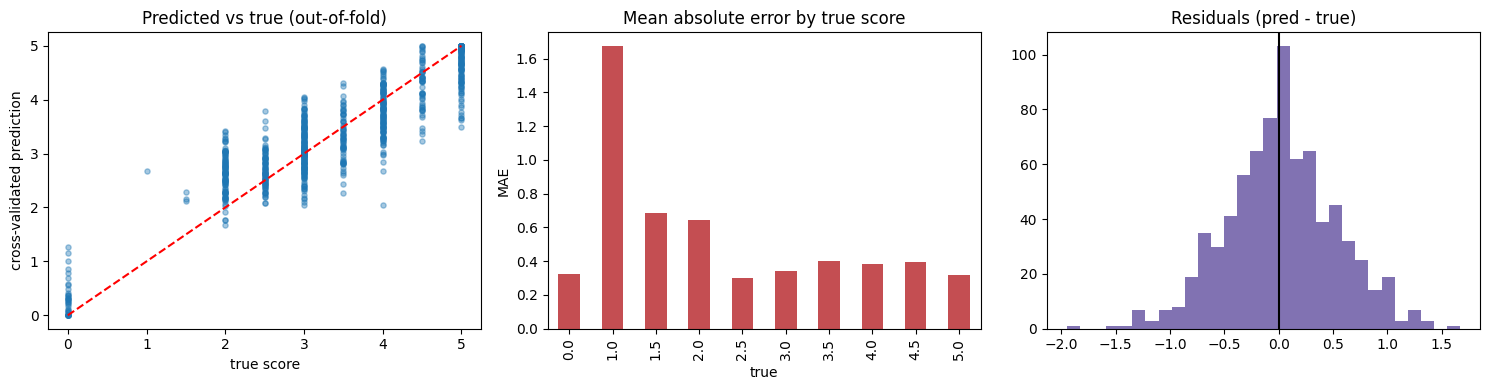

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y, cv_pred, alpha=0.4, s=14); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("true score"); ax[0].set_ylabel("cross-validated prediction"); ax[0].set_title("Predicted vs true (out-of-fold)")

err = cv_pred - y
tmp = pd.DataFrame({"true": y, "abs_err": np.abs(err)}).groupby("true")["abs_err"].mean()
tmp.plot.bar(ax=ax[1], color="#C44E52"); ax[1].set_title("Mean absolute error by true score"); ax[1].set_ylabel("MAE")

ax[2].hist(err, bins=30, color="#8172B2"); ax[2].set_title("Residuals (pred - true)"); ax[2].axvline(0, color="k")
plt.tight_layout(); plt.show()

## 9. Final model and submission

For the final predictions both models are refit on all 769 training clips and averaged. Predictions are clipped to the valid 0 to 5 range and saved in the same format as the sample submission.

In [25]:
test_pred = predict_final(te_df)
print("test clips predicted below 0.5:", int((test_pred < 0.5).sum()), "of", len(test_pred))

sub = pd.DataFrame({"filename": te_df["filename"], "label": test_pred})
if SAMPLE_SUB:                                   # follow the official column names, ids and row order
    ss = pd.read_csv(SAMPLE_SUB[0])
    print("sample_submission columns:", list(ss.columns), "| rows:", len(ss))
    print(ss.head(3).to_string(index=False))
    id_col, val_col = ss.columns[0], ss.columns[1]

    # compare ids ignoring case, spaces and a ".wav" ending, in case the formats differ slightly
    norm = lambda v: str(v).strip().lower().replace(".wav", "")
    mine = dict(zip(sub["filename"].map(norm), sub["label"]))
    ss_ids = ss[id_col].map(norm)
    only_mine, only_sample = set(mine) - set(ss_ids), set(ss_ids) - set(mine)
    if only_mine or only_sample or len(ss) != len(mine):
        print("ids only in my predictions :", sorted(only_mine)[:10], "... total", len(only_mine))
        print("ids only in sample file    :", sorted(only_sample)[:10], "... total", len(only_sample))
        print("WARNING: sample_submission.csv does not list the same clips as test.csv "
              f"({len(ss)} ids vs {len(mine)}). Falling back to the clips in test.csv, "
              "using the sample file's column names.")
        sub = sub.rename(columns={"filename": id_col, "label": val_col})[[id_col, val_col]]
    else:
        sub = ss[[id_col]].copy()                # ids match: keep the sample file's own ids and order
        sub[val_col] = ss_ids.map(mine).values
sub.to_csv(os.path.join(WORK, "submission.csv"), index=False)
print(sub.shape); sub.head()

test clips predicted below 0.5: 0 of 216
sample_submission columns: ['filename', 'label'] | rows: 204
      filename  label
 audio_804.wav     -1
audio_1028.wav     -1
 audio_865.wav     -1
ids only in my predictions : ['audio_0', 'audio_1', 'audio_10', 'audio_100', 'audio_101', 'audio_102', 'audio_103', 'audio_104', 'audio_105', 'audio_106'] ... total 191
ids only in sample file    : ['audio_1001', 'audio_1006', 'audio_1011', 'audio_1025', 'audio_1028', 'audio_1039', 'audio_1041', 'audio_1046', 'audio_1055', 'audio_1059'] ... total 179
(216, 2)


,filename,label
0,audio_128.wav,3.238588
1,audio_156.wav,4.177330
2,audio_19.wav,4.576626
3,audio_108.wav,2.236315
4,audio_206.wav,2.160322


## 10. Report

**Approach.** Each recording is turned into text with Whisper (small), and I also keep what the audio itself sounds like. From the text I build counts that describe fluency and structure (words, sentences, sentence length, vocabulary variety, fillers, repeated words, repetition measures), the GPT-2 loss of the transcript, and a MiniLM sentence embedding. From the audio I take simple measurements (length, share of speech, number of pauses, loudness) and, most importantly, embeddings from pretrained speech encoders: the Whisper encoders (small, medium and large-v3-turbo) and WavLM-large. Each encoder is read at several layers, and for each layer I keep the average and the spread over time. The hand-made block has 24 columns, 18 of them described above and 6 from a small language model that read the transcript against the rubric. That language-model step did not help (cross-validated RMSE 0.559 with it, 0.557 without), so it is only a documented experiment.

On top of the features sit two simple models, a Ridge regression and an SVR, whose predictions are averaged. The text embedding is reduced to 24 PCA components and the audio embeddings to 96, the Ridge strength is 30 and the SVR setting C is 3 (all chosen with cross-validation). The final prediction is the average of three such models, each using a different set of audio features: the medium encoder at its last and middle layers, WavLM-large at layer 16, and the medium encoder at layers 16, 20 and 24. Averaging them lowered the cross-validated RMSE from 0.522 (best single set) to 0.514, because the sets make partly different mistakes.

**Preprocessing.** Audio is loaded as 16 kHz mono, and clips are cut into 30-second pieces for the Whisper encoders. Transcripts and embeddings are saved to disk so the slow steps run once. Missing language-model values (nearly empty transcripts) are filled with the median and flagged. The final predictions are clipped to the range 0 to 5. All 37 clips with a score of 0 come from a separate block of file numbers and look like noise recordings (no pauses, loud, repetitive text that Whisper invented). They stay in training, and a separate two-step model for them was tested and was not better, so it is not used.

**Results.** Training RMSE is **0.3294** (Pearson 0.967). With 5-fold cross-validation repeated three times, the RMSE is 0.5140 with a Pearson correlation of 0.911 on all clips, and 0.5160 with a Pearson correlation of 0.862 on the normal clips (score above 0). A model that always predicts the mean has an RMSE of 1.238 on all clips and 1.014 on the normal clips. Without any encoder embeddings the normal-clip RMSE was 0.706 (Pearson 0.718), and with the medium encoder alone it was 0.562 (Pearson 0.832), so the audio embeddings are where most of the gain came from. Among the layers, layer 8 was clearly worse (0.627 for medium, 0.621 for WavLM) and layers 12 to 24 were all close (about 0.56 to 0.57). The gap between the training and cross-validated RMSE is 0.185, so there is a noticeable amount of overfitting: the model fits the clips it has seen better than new ones. On the public part of the competition leaderboard (about 60 percent of the test clips) this submission scored 0.3965.

**What the plots show.** The cross-validated predictions follow the diagonal, and the residuals are roughly centred on zero, mostly within one point. The clips with a score of 0 are predicted close to 0 (mostly below 0.5). The error is about 0.3 to 0.4 for scores from 2.5 to 5, and larger for the rare low scores (about 0.65 for scores 1.5 and 2, and 1.7 for the single clip scored 1), where the model has very little to learn from. Predictions for the top scores are somewhat pulled toward the middle.

**Limitations.** There are only 769 labelled clips, human grading is noisy, and scores of 1 and 1.5 are almost absent. Whisper tends to tidy up grammar mistakes, so the text carries less signal than the audio. I chose the features and settings with the same cross-validation folds, so the cross-validated numbers are a little optimistic, and the leaderboard moved less than they did. A later version with a wider search, an extra tree-based model and more options scored worse on the leaderboard (0.42), so I kept this simpler one.

**What I would try next.** Checking whether the test clips differ from the training clips (for example in length), fine-tuning the last layers of an encoder with strong regularisation, and adding more differently trained encoders to the average.
